Завантаження файлу annotations.coco.json

In [ ]:
import requests
import json
import os

annotations_url = (
    "https://ftp.ebi.ac.uk/pub/databases/biostudies/"
    "S-BIAD/778/S-BIAD3778/Files/annotations/annotations.coco.json"
)

annotations_path = "/content/annotations.coco.json"

response = requests.get(annotations_url)

print("HTTP status:", response.status_code)
print("Downloaded:", len(response.content) / 1024 / 1024, "MB")

with open(annotations_path, "wb") as f:
    f.write(response.content)

print("File saved:", annotations_path)

HTTP status: 200
Downloaded: 106.31419372558594 MB
File saved: /content/annotations.coco.json


Вміст файлу annotations.coco.json

In [ ]:
with open(annotations_path, "r") as f:
    coco = json.load(f)

print("Keys:", coco.keys())

print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))
print("Categories:", coco["categories"])

Keys: dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
Images: 2255
Annotations: 8128
Categories: [{'id': 1, 'name': 'cell', 'supercategory': 'biological_structure'}]


Опис першого зображення

In [ ]:
image_id = coco["images"][0]["id"]

image_info = coco["images"][0]

print("Image ID:", image_id)
print("File:", image_info["file_name"])
print("Size:", image_info["width"], "x", image_info["height"])
print("Day:", image_info["timepoint_days"])
print("Cryoprotectant:", image_info["cryoprotectant"])
print("Concentration:", image_info["concentration_pct"])
print("Well:", image_info["well_id"])
print("Image type:", image_info["image_type"])

Image ID: 1
File: images/day_06_DMSO/well_D2_DMSO_10pct/day_06_DMSO_10pct_well_D2_before_x40.ome.tiff
Size: 2572 x 1956
Day: 6
Cryoprotectant: DMSO
Concentration: 10
Well: D2
Image type: before


Кількість анотацій для першого зображення

In [ ]:
image_annotations = [
    ann for ann in coco["annotations"]
    if ann["image_id"] == image_id
]

print("Annotations for this image:", len(image_annotations))

Annotations for this image: 6


Завантаження зображення

In [ ]:
image_path = image_info["file_name"]

print(image_path)


images/day_06_DMSO/well_D2_DMSO_10pct/day_06_DMSO_10pct_well_D2_before_x40.ome.tiff


In [ ]:
base_url = (
    "https://ftp.ebi.ac.uk/pub/databases/biostudies/"
    "S-BIAD/778/S-BIAD3778/Files/"
)

image_url = base_url + image_path

print(image_url)


https://ftp.ebi.ac.uk/pub/databases/biostudies/S-BIAD/778/S-BIAD3778/Files/images/day_06_DMSO/well_D2_DMSO_10pct/day_06_DMSO_10pct_well_D2_before_x40.ome.tiff


In [ ]:
image_response = requests.get(image_url)

print("HTTP status:", image_response.status_code)
print("Size:", len(image_response.content) / 1024 / 1024, "MB")

image_local_path = "/content/test_image.ome.tiff"

with open(image_local_path, "wb") as f:
    f.write(image_response.content)

print("Saved:", image_local_path)

HTTP status: 200
Size: 14.394607543945312 MB
Saved: /content/test_image.ome.tiff


Встановлення бібліотеки для читання

In [ ]:
!pip install tifffile -q

In [ ]:
import tifffile
import matplotlib.pyplot as plt
import numpy as np

image = tifffile.imread(image_local_path)

print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("Min:", image.min())
print("Max:", image.max())

ERROR:tifffile:<tifffile.TiffFile 'test_image.ome.tiff'> OME series raised ParseError('not well-formed (invalid token): line 1, column 62')


Shape: (1956, 2572, 3)
Dtype: uint8
Min: 0
Max: 244


Оригінальне зображення

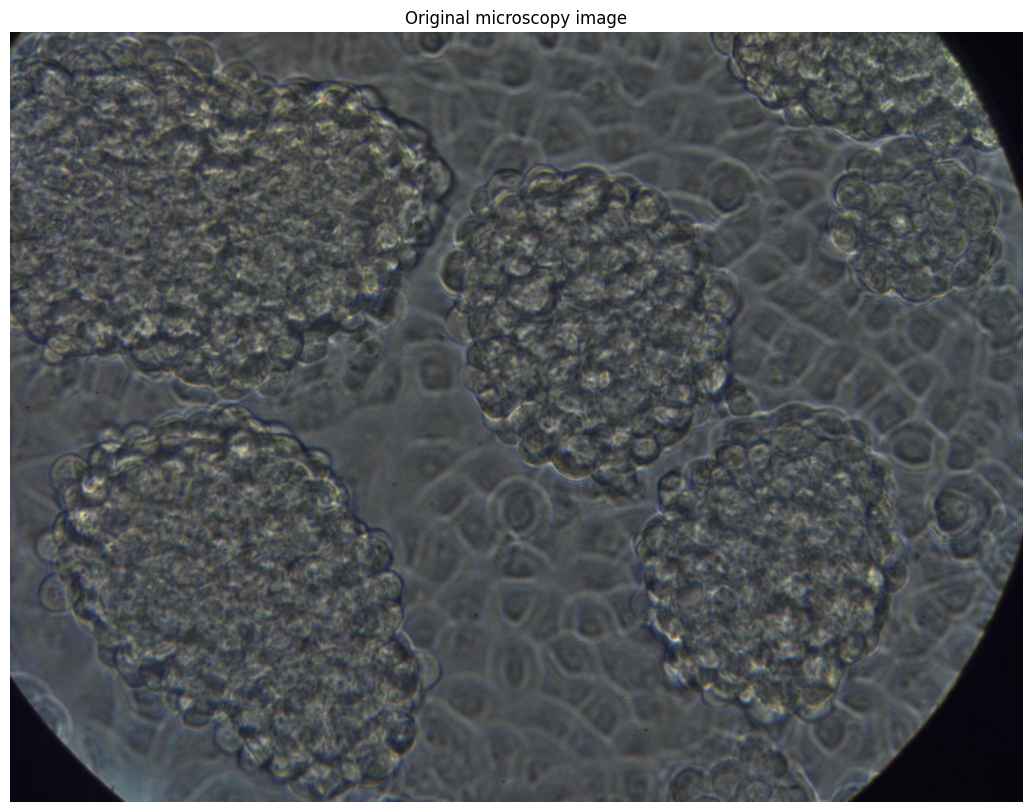

In [ ]:
plt.figure(figsize=(14, 10))

plt.imshow(image, cmap="gray")

plt.axis("off")
plt.title("Original microscopy image")

plt.show()

Малювання контуру поверх зображень

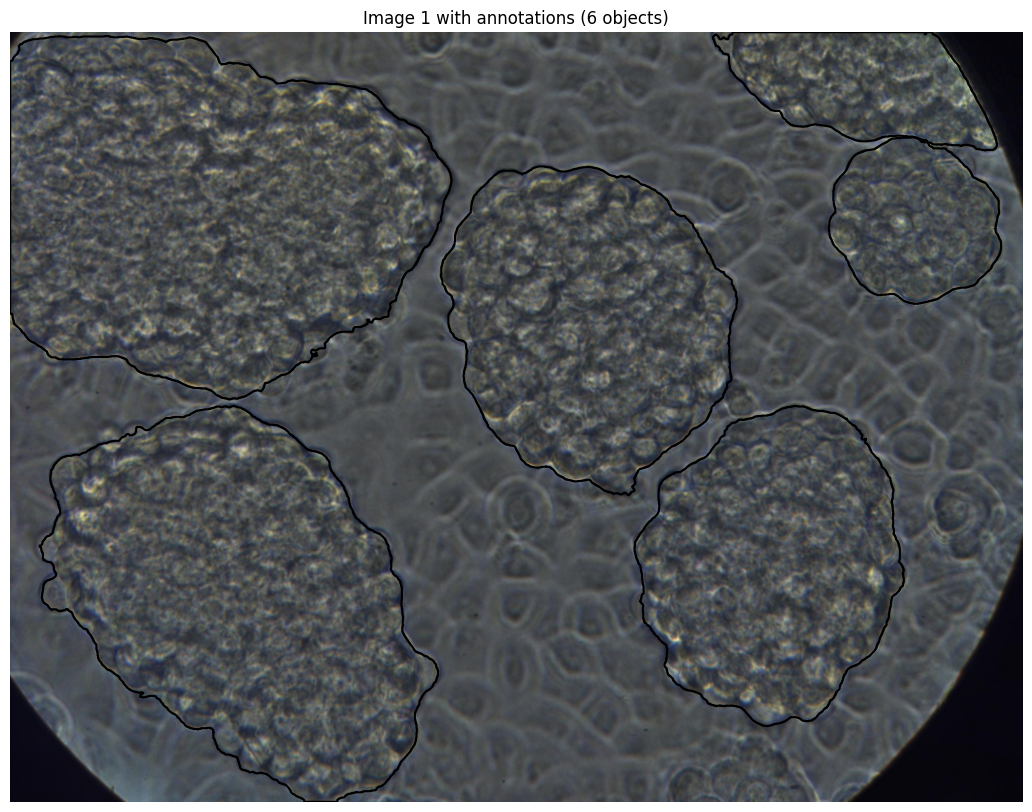

In [ ]:
from matplotlib.patches import Polygon

plt.figure(figsize=(14, 10))

plt.imshow(image, cmap="gray")

for ann in image_annotations:

    segmentation = ann["segmentation"]

    for polygon in segmentation:

        polygon = np.array(polygon).reshape(-1, 2)

        plt.gca().add_patch(
            Polygon(
                polygon,
                fill=False,
                linewidth=1.5
            )
        )

plt.axis("off")
plt.title(
    f"Image {image_id} with annotations "
    f"({len(image_annotations)} objects)"
)

plt.show()

Прямокутні області

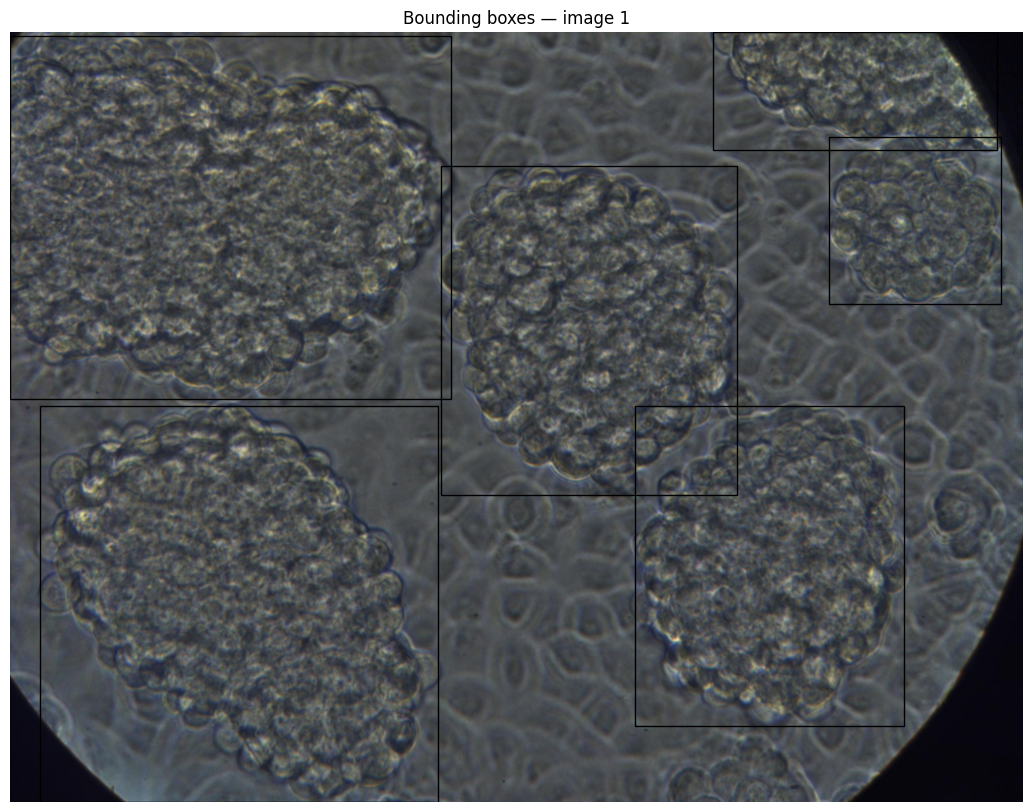

In [ ]:
from matplotlib.patches import Rectangle

plt.figure(figsize=(14, 10))

plt.imshow(image, cmap="gray")

ax = plt.gca()

for ann in image_annotations:

    x, y, width, height = ann["bbox"]

    rectangle = Rectangle(
        (x, y),
        width,
        height,
        fill=False,
        linewidth=1
    )

    ax.add_patch(rectangle)

plt.axis("off")
plt.title(
    f"Bounding boxes — image {image_id}"
)

plt.show()

Маска без оригінального зображення

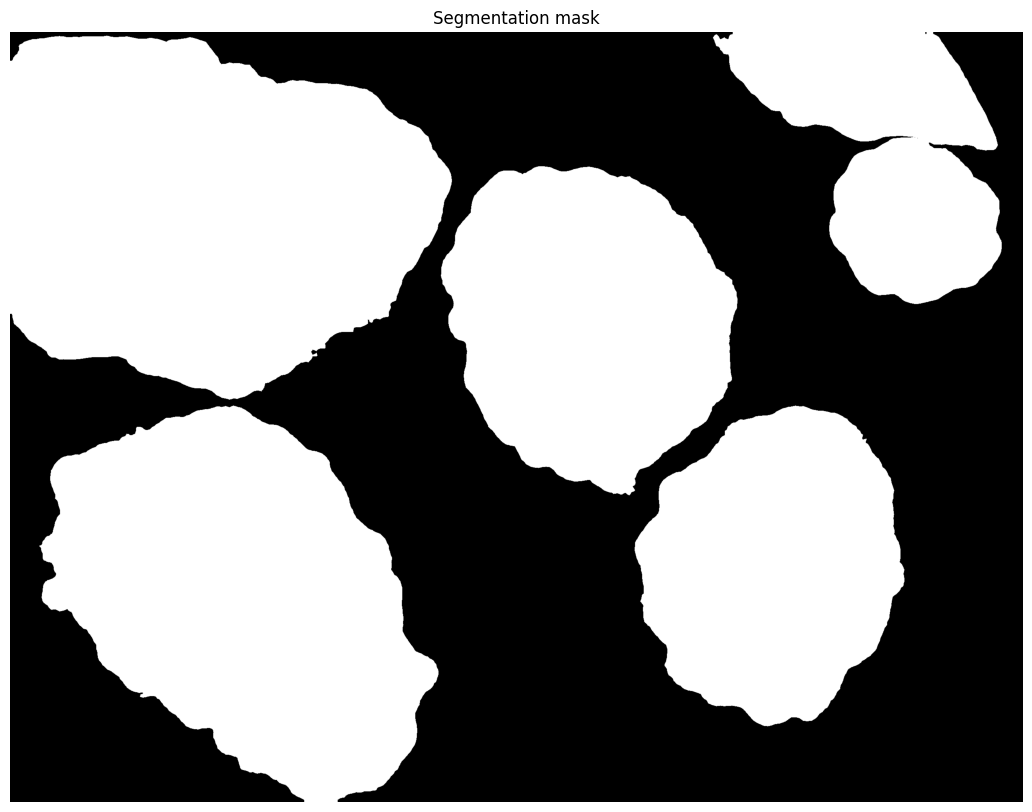

In [ ]:
from PIL import Image, ImageDraw

mask = Image.new(
    "L",
    (image_info["width"], image_info["height"]),
    0
)

draw = ImageDraw.Draw(mask)

for ann in image_annotations:

    for polygon in ann["segmentation"]:

        polygon = np.array(polygon).reshape(-1, 2)

        draw.polygon(
            [tuple(point) for point in polygon],
            fill=255
        )

mask_array = np.array(mask)

plt.figure(figsize=(14, 10))
plt.imshow(mask_array, cmap="gray")
plt.axis("off")
plt.title("Segmentation mask")
plt.show()

Оригінал + напівпрозора маска

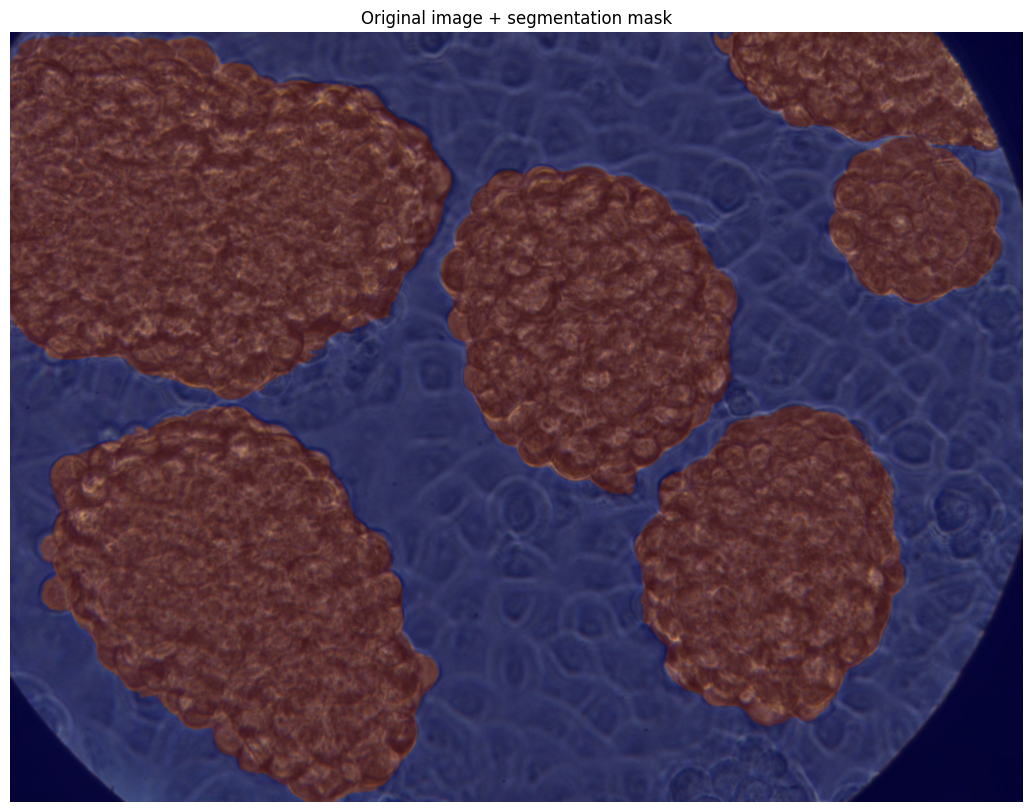

In [ ]:
plt.figure(figsize=(14, 10))

plt.imshow(image, cmap="gray")

plt.imshow(
    mask_array,
    cmap="jet",
    alpha=0.35
)

plt.axis("off")
plt.title("Original image + segmentation mask")

plt.show()

# Аудит розмітки

In [ ]:

from collections import Counter, defaultdict
import pandas as pd

# 1. All images and annotations
images = coco["images"]
annotations = coco["annotations"]

all_image_ids = {img["id"] for img in images}
annotated_image_ids = {
    ann["image_id"] for ann in annotations
}

images_with_annotations = all_image_ids & annotated_image_ids
images_without_annotations = all_image_ids - annotated_image_ids
unknown_image_ids = annotated_image_ids - all_image_ids

print(f"Total images: {len(images)}")
print(f"Total annotations: {len(annotations)}")
print(f"Images with annotations: {len(images_with_annotations)}")
print(f"Images without annotations: {len(images_without_annotations)}")
print(f"Annotations linked to unknown image IDs: {len(unknown_image_ids)}")

if images:
    print(
        "Share of images annotated at least once: "
        f"{100 * len(images_with_annotations) / len(images):.2f}%"
    )


Total images: 2255
Total annotations: 8128
Images with annotations: 2255
Images without annotations: 0
Annotations linked to unknown image IDs: 0
Share of images annotated at least once: 100.00%


Розподіл розміток між умовами експерименту

In [ ]:

# 2. One row per image, including images with zero annotations
annotation_counts = Counter(
    ann["image_id"] for ann in annotations
)

rows = []

for img in images:
    rows.append({
        "image_id": img["id"],
        "file_name": img["file_name"],
        "timepoint_days": img.get("timepoint_days"),
        "cryoprotectant": img.get("cryoprotectant"),
        "concentration_pct": img.get("concentration_pct"),
        "well_id": img.get("well_id"),
        "image_type": img.get("image_type"),
        "frame_number": img.get("frame_number"),
        "n_annotations": annotation_counts.get(img["id"], 0)
    })

df_images = pd.DataFrame(rows)

# Summary by experimental conditions
summary = (
    df_images
    .groupby(
        ["timepoint_days", "cryoprotectant", "concentration_pct"],
        dropna=False
    )
    .agg(
        total_images=("image_id", "count"),
        annotated_images=("n_annotations",
                          lambda x: (x > 0).sum()),
        total_annotations=("n_annotations", "sum"),
        mean_annotations_per_image=("n_annotations", "mean")
    )
    .reset_index()
)

summary["annotated_image_pct"] = (
    100 * summary["annotated_images"] / summary["total_images"]
)

display(summary)


,timepoint_days,cryoprotectant,concentration_pct,total_images,annotated_images,total_annotations,mean_annotations_per_image,annotated_image_pct
0,6,DMSO,5.0,123,123,615,5.000000,100.0
1,6,DMSO,10.0,82,82,493,6.012195,100.0
2,6,PEG1500,5.0,82,82,329,4.012195,100.0
3,6,PEG1500,7.5,41,41,124,3.024390,100.0
4,6,PEG1500,10.0,82,82,369,4.500000,100.0
5,6,PROH,5.0,41,41,82,2.000000,100.0
6,6,PROH,7.5,82,82,123,1.500000,100.0
7,6,PROH,10.0,82,82,328,4.000000,100.0
8,6,glycerol,5.0,164,164,780,4.756098,100.0
9,6,glycerol,7.5,164,164,738,4.500000,100.0


In [ ]:

# 3. How many annotated objects are present per image?
print(df_images["n_annotations"].describe())

print("\nImages grouped by annotation count:")
display(
    df_images["n_annotations"]
    .value_counts()
    .sort_index()
    .rename_axis("annotations_per_image")
    .reset_index(name="number_of_images")
)


count    2255.000000
mean        3.604435
std         2.008098
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max         9.000000
Name: n_annotations, dtype: float64

Images grouped by annotation count:


,annotations_per_image,number_of_images
0,1,246
1,2,695
2,3,327
3,4,248
4,5,245
5,6,288
6,7,83
7,8,122
8,9,1


Визначення збалансованості датасету

In [ ]:
# Check how images are distributed across experimental conditions

print("Images by timepoint:")
display(
    df_images.groupby("timepoint_days")
    .agg(
        images=("image_id", "count"),
        annotations=("n_annotations", "sum")
    )
)

print("Images by cryoprotectant:")
display(
    df_images.groupby("cryoprotectant")
    .agg(
        images=("image_id", "count"),
        annotations=("n_annotations", "sum")
    )
)

print("Images by image type:")
display(
    df_images.groupby("image_type", dropna=False)
    .agg(
        images=("image_id", "count"),
        annotations=("n_annotations", "sum")
    )
)

print("Unique wells:", df_images["well_id"].nunique())

print("Images by frame number:")
display(
    df_images.groupby("frame_number", dropna=False)
    .size()
    .rename("number_of_images")
    .reset_index()
    .sort_values("frame_number")
)

Images by timepoint:


,images,annotations
timepoint_days,,
6,1107,5090
7,533,1355
20,615,1683


Images by cryoprotectant:


,images,annotations
cryoprotectant,,
DMSO,656,2216
PEG1500,492,1439
PROH,451,1271
glycerol,656,3202


Images by image type:


,images,annotations
image_type,,
before,55,208
later,2200,7920


Unique wells: 29
Images by frame number:


,frame_number,number_of_images
0,0,110
1,1,55
2,2,55
3,3,55
4,4,55
5,5,55
6,6,55
7,7,55
8,8,55
9,9,55


Вибіркова перевірка даних

In [ ]:
import random
import pandas as pd
from collections import Counter

# Count annotations per image
annotation_counts = Counter(
    ann["image_id"] for ann in coco["annotations"]
)

# Create a table with image metadata and annotation counts
audit_df = pd.DataFrame([
    {
        "image_id": img["id"],
        "file_name": img["file_name"],
        "timepoint_days": img.get("timepoint_days"),
        "cryoprotectant": img.get("cryoprotectant"),
        "concentration_pct": img.get("concentration_pct"),
        "well_id": img.get("well_id"),
        "image_type": img.get("image_type"),
        "frame_number": img.get("frame_number"),
        "n_annotations": annotation_counts.get(img["id"], 0)
    }
    for img in coco["images"]
])

# Group images by annotation count
audit_df["annotation_group"] = audit_df["n_annotations"].apply(
    lambda n: str(n) if n <= 3 else "4+"
)

# Select up to 10 images from each group
random.seed(42)

selected_parts = []

for group in ["1", "2", "3", "4+"]:
    group_df = audit_df[
        audit_df["annotation_group"] == group
    ]

    n = min(10, len(group_df))

    if n > 0:
        selected_parts.append(
            group_df.sample(n=n, random_state=42)
        )

audit_sample = pd.concat(
    selected_parts,
    ignore_index=True
)

print("Selected images:", len(audit_sample))

display(
    audit_sample[
        [
            "image_id",
            "file_name",
            "timepoint_days",
            "cryoprotectant",
            "well_id",
            "frame_number",
            "n_annotations"
        ]
    ]
)

Selected images: 40


,image_id,file_name,timepoint_days,cryoprotectant,well_id,frame_number,n_annotations
0,567,images/day_06_PROH/well_C4_PROH_7.5pct/day_06_...,6,PROH,C4,32,1
1,540,images/day_06_PROH/well_C4_PROH_7.5pct/day_06_...,6,PROH,C4,5,1
2,1576,images/day_07_PROH/well_D5_PROH_7.5pct/day_07_...,7,PROH,D5,16,1
3,1235,images/day_07_PEG1500/well_A5_PEG1500_5pct/day...,7,PEG1500,A5,3,1
4,1550,images/day_07_PROH/well_C7_PROH_5pct/day_07_PR...,7,PROH,C7,31,1
5,1573,images/day_07_PROH/well_D5_PROH_7.5pct/day_07_...,7,PROH,D5,13,1
6,1589,images/day_07_PROH/well_D5_PROH_7.5pct/day_07_...,7,PROH,D5,29,1
7,1253,images/day_07_PEG1500/well_A5_PEG1500_5pct/day...,7,PEG1500,A5,21,1
8,543,images/day_06_PROH/well_C4_PROH_7.5pct/day_06_...,6,PROH,C4,8,1
9,2243,images/day_20_glycerol/well_B6_glycerol_7.5pct...,20,glycerol,B6,27,1


Приклади зображень та контурів масок

In [ ]:

import requests
import numpy as np
import matplotlib.pyplot as plt
import tifffile

from matplotlib.patches import Polygon
from collections import defaultdict
from io import BytesIO

BASE_URL = (
    "https://ftp.ebi.ac.uk/pub/databases/biostudies/"
    "S-BIAD/778/S-BIAD3778/Files/"
)

# Index annotations by image ID
annotations_by_image = defaultdict(list)

for ann in coco["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)


def load_image_for_display(image_url):
    response = requests.get(image_url, timeout=60)
    response.raise_for_status()

    # Suppress warnings about potentially malformed OME metadata.
    # The pixel array may still be readable.
    with tifffile.TiffFile(
        BytesIO(response.content),
        is_ome=False
    ) as tif:
        image = tif.asarray()

    image = np.squeeze(image)

    # Support grayscale and RGB images
    if image.ndim == 2:
        display_image = image
        is_rgb = False

    elif image.ndim == 3 and image.shape[-1] in (3, 4):
        display_image = image
        is_rgb = True

    elif image.ndim == 3 and image.shape[0] in (3, 4):
        # Convert channel-first to channel-last
        display_image = np.moveaxis(image, 0, -1)
        is_rgb = True

    else:
        raise ValueError(
            f"Unsupported image shape: {image.shape}"
        )

    return display_image, is_rgb


# Display images in batches of five
BATCH_SIZE = 5

for start in range(0, len(audit_sample), BATCH_SIZE):
    batch = audit_sample.iloc[start:start + BATCH_SIZE]

    fig, axes = plt.subplots(
        len(batch),
        2,
        figsize=(14, 5 * len(batch)),
        squeeze=False
    )

    for row_idx, (_, row) in enumerate(batch.iterrows()):
        image_id = int(row["image_id"])
        image_url = BASE_URL + row["file_name"]

        try:
            image, is_rgb = load_image_for_display(image_url)
        except Exception as e:
            print(f"Could not load image {image_id}: {e}")
            axes[row_idx, 0].axis("off")
            axes[row_idx, 1].axis("off")
            continue

        # Display original image
        if is_rgb:
            axes[row_idx, 0].imshow(image)
            axes[row_idx, 1].imshow(image)
        else:
            vmin, vmax = np.percentile(image, [1, 99])
            axes[row_idx, 0].imshow(
                image, cmap="gray", vmin=vmin, vmax=vmax
            )
            axes[row_idx, 1].imshow(
                image, cmap="gray", vmin=vmin, vmax=vmax
            )

        axes[row_idx, 0].set_title(
            f"Image ID: {image_id}\n"
            f"Annotations: {row['n_annotations']}"
        )
        axes[row_idx, 0].axis("off")

        # Overlay annotation contours
        for ann in annotations_by_image[image_id]:
            for polygon in ann.get("segmentation", []):
                points = np.asarray(polygon).reshape(-1, 2)

                if len(points) >= 3:
                    axes[row_idx, 1].add_patch(
                        Polygon(
                            points,
                            closed=True,
                            fill=False,
                            edgecolor="red",
                            linewidth=1.2
                        )
                    )

        axes[row_idx, 1].set_title(
            f"Annotation contours — ID: {image_id}"
        )
        axes[row_idx, 1].axis("off")

    plt.tight_layout()
    plt.show()
